In [1]:
import keras_ocr
from tensorflow import keras
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib import transforms
import cv2

from PIL import Image
import numpy as np
import random
import tensorflow_probability as tfp

from sklearn.linear_model import LinearRegression

import math

In [2]:
import keras_cv

Using TensorFlow backend


C:\Users\sures\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
image_file = "Images/image_50402305.JPG"

In [4]:
tf_img = tf.io.read_file("Images/image_50402305.JPG")
tf_img = tf.image.decode_jpeg(tf_img, 1)

In [5]:
pipeline = keras_ocr.pipeline.Pipeline()

images = [keras_ocr.tools.read("Images/image_50402305.JPG")]

prediction_groups = pipeline.recognize(images) # Note that an image from the directory can be passed here

Looking for C:\Users\sures\.keras-ocr\craft_mlt_25k.h5

Instructions for updating:
Use `tf.image.resize(...method=ResizeMethod.BILINEAR...)` instead.

Looking for C:\Users\sures\.keras-ocr\crnn_kurapan.h5
8/8 [==============================] - 22s 2s/step


In [6]:
prediction_groups = prediction_groups[0]

---

In [7]:
# Define functions for dealing with images

image_width = 512 # 128
image_height = 128 # 32

def GetBox(Pred):
    x_max = 0
    x_min = 10000
    y_max = 0
    y_min = 10000

    for i in Pred[1]:
        x_max = max(i[0], x_max)
        x_min = min(i[0], x_min)
        y_max = max(i[1], y_max)
        y_min = min(i[1], y_min)

    # Each of these 4 variables is an edge of the box
    
    return x_max, x_min, y_max, y_min

def distortion_free_resize(image, img_size):
    w, h = img_size
    image = tf.image.resize(image, size=(h, w), preserve_aspect_ratio=True)

    # Check tha amount of padding needed to be done.
    pad_height = h - tf.shape(image)[0]
    pad_width = w - tf.shape(image)[1]

    # Only necessary if you want to do same amount of padding on both sides.
    if pad_height % 2 != 0:
        height = pad_height // 2
        pad_height_top = height + 1
        pad_height_bottom = height
    else:
        pad_height_top = pad_height_bottom = pad_height // 2

    if pad_width % 2 != 0:
        width = pad_width // 2
        pad_width_left = width + 1
        pad_width_right = width
    else:
        pad_width_left = pad_width_right = pad_width // 2

    image = tf.pad(
        image,
        paddings=[
            [pad_height_top, pad_height_bottom],
            [pad_width_left, pad_width_right],
            [0, 0],
        ],
    )

    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.image.flip_left_right(image)
    return image

def preprocess_image(image, img_size=(image_width, image_height)):
    image = distortion_free_resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

def DisplayWord(word):
    word = tf.reshape(word, (image_width, image_height, 1))
    
    word = tf.image.flip_left_right(word)
    word = tf.transpose(word, perm=[1, 0, 2])
    # word = (word * 255.0).numpy().clip(0, 255).astype(np.uint8)

    plt.imshow(word[:, :, 0], cmap='gray')
    plt.show()

def WordBox(Pred):
    x_max, x_min, y_max, y_min = GetBox(Pred)

    print("The word is identified as: ", Pred[0])

    print(int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    word = tf.image.crop_to_bounding_box(tf_img, int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    return preprocess_image(word) # This returns a tensorflow image object

The word is identified as:  eunaleace
638 572 81 256


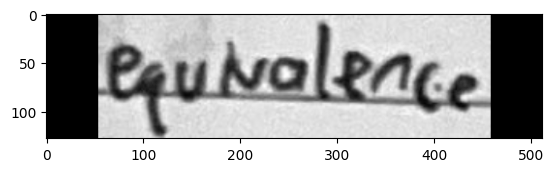

In [8]:
res = WordBox(prediction_groups[66])
DisplayWord(res)

In [9]:
word = res # This will be processed in the below code

# Pre-processing

In [10]:
from skimage.morphology import medial_axis, skeletonize, thin

from skimage.util import invert
import skimage

Make the image black background on white

In [11]:
def BgChange(word, CleaningCoefficient):

    # The higher the CleaningCoefficient, the more of the dimmer features that are cleaned out

    image = [ [ 0 for i in range(len(word[i])) ]  for i in range(len(word))]

    for i in range(len(word)):
        for j in range(len(word[i])):
            # if word[i][j][0] > 0.6:
            #     tf.print(word[i][j][0])
            #     image[i][j] = [1]
            # else:
            #     image[i][j] = [0]

            temp = float(word[i][j][0]) * CleaningCoefficient

            if temp == 0:
                temp = 1

            if temp > 1:
                temp = 1

            image[i][j] = temp

    image = tf.constant(image)

    image = skimage.img_as_float(image)
    image = invert(image)

    DisplayWord(image)

    return image

In [12]:
def BgChangeOptimised(word, CleaningCoefficient):
    word = word * CleaningCoefficient

    word = tf.constant(np.where(word == 0, 1, word))

    word = tf.where(word > 1, 1, word)

    word = skimage.img_as_float(word)
    word = invert(word)

    DisplayWord(word)

    return tf.constant(word)
    

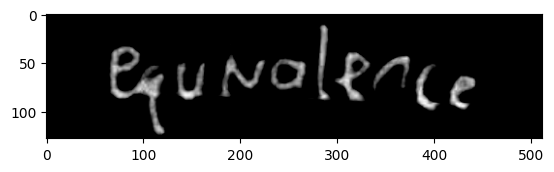

In [13]:
image = BgChangeOptimised(word, 3.5)

Remove Line (hasn't worked out as of yet)

In [14]:
# A = BgChange(word, 1.5)
# B = BgChange(word, 3)

# C = A - 2 * B

# DisplayWord(C)



In [15]:
line_thickness=2

img = res

# Apply binary thresholding to get a binary image
binary_image = tf.where(img < 0.5, 0.0, 1.0)

# Create a horizontal kernel
kernel = tf.ones((1, line_thickness, 1, 1), dtype=tf.float32)

# Apply 1D convolution to detect horizontal lines
lines_detected = tf.nn.conv2d(binary_image[None, ..., None], kernel, strides=[1, 1, 1, 1], padding='SAME')[0, ..., 0]

# Set pixels corresponding to detected lines to 0
result_image = tf.where(lines_detected > 0, 0.0, img)


Slope removal

In [16]:
def RotateImage(image, angle):
    image = tf.reshape(image, [image_width,image_height])
    im = image.numpy()
    im = Image.fromarray(im)
    im_rotated = im.rotate(angle=angle)
    im = np.asarray(im_rotated)
    image_r = tf.convert_to_tensor(im)

    return image_r

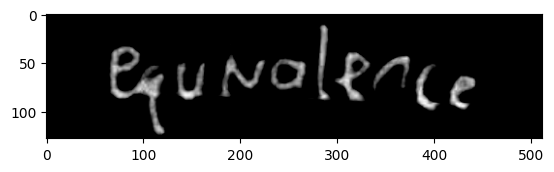

In [17]:
DisplayWord(image)

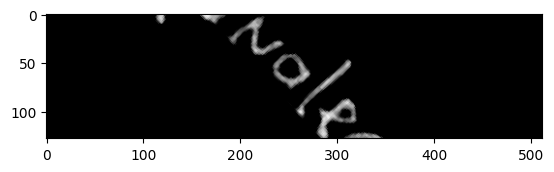

In [18]:
DisplayWord(RotateImage(image, -45))

In [19]:
image = tf.reshape(image, [image_width,image_height])
if tf.where(image[200] != 0).shape == (0,1):
    print("empty")
else:
    print(tf.where(image[200] != 0)[-1][0].numpy())

67


In [20]:
def HorizontallHistorgram(image):
    image = tf.reshape(image, [image_width,image_height])
    image = tf.where(image != 0, 1, image)
    
    sums = tf.map_fn(lambda x: tf.math.reduce_sum(x), image)

    dists = [] # This stores the distance between the top and the bottom pixel

    for i in range(len(image)):
        non_zero = tf.where(image[i] != 0)
        
        if non_zero.shape == (0,1):
            dists.append(0)
        else:
            top = non_zero[0][0].numpy()
            bottom = non_zero[-1][0].numpy()
            dists.append(bottom - top + 1)

    dists = tf.constant(dists, dtype=tf.float32)

    Hw = tf.divide(sums, dists)

    return tf.where(tf.math.logical_not(tf.math.is_finite(Hw)), tf.zeros_like(Hw), Hw)

    # return sums, dists

In [21]:
HorizontallHistorgram(image)

<tf.Tensor: shape=(512,), dtype=float32, numpy=
array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.6       , 1.        , 1.        , 1.        , 1.        ,
       1.     

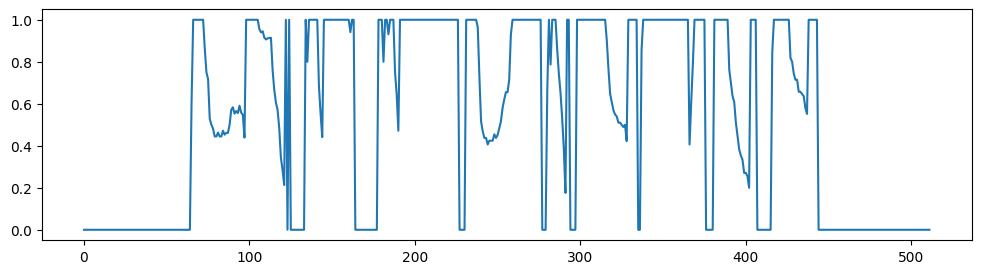

In [22]:
plt.figure(figsize=(12,3))
plt.plot(HorizontallHistorgram(image))

In [23]:
def VerticalHistorgram(image):
    image = tf.reshape(image, [image_width,image_height])
    sums = tf.reduce_sum(image, axis=0)
    return sums

In [24]:
VerticalHistorgram(image)

<tf.Tensor: shape=(128,), dtype=float32, numpy=
array([ 0.       ,  0.       ,  0.       ,  0.5941572,  2.2260845,
        4.120578 ,  5.2517586,  6.045109 ,  6.1485214,  6.002848 ,
        5.7342224,  5.26488  ,  4.409936 ,  3.5291562,  3.3117683,
        3.2763329,  3.3092268,  3.3958528,  3.369318 ,  3.1557033,
        2.8127787,  2.4663527,  2.4680684,  2.6131825,  2.9426098,
        3.024448 ,  3.1011891,  3.17106  ,  3.9427073,  6.4241457,
       10.0100155, 15.1172085, 21.00943  , 25.354696 , 28.307606 ,
       28.734055 , 22.4419   , 19.952084 , 22.028234 , 27.021446 ,
       34.074596 , 42.808517 , 50.744526 , 59.205276 , 62.978455 ,
       66.50261  , 66.77429  , 62.64947  , 56.567772 , 52.160763 ,
       53.356316 , 58.38488  , 63.004543 , 66.560745 , 69.340416 ,
       69.19597  , 68.473816 , 68.97882  , 66.94818  , 64.45291  ,
       61.149105 , 53.87854  , 48.581974 , 45.601246 , 44.90141  ,
       45.013985 , 44.254715 , 45.350056 , 47.63793  , 50.47902  ,
       54.2686

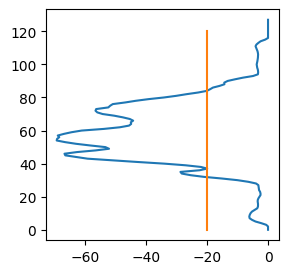

In [25]:
plt.figure(figsize=(3,3))
base = plt.gca().transData
rot = transforms.Affine2D().rotate_deg(90)

Vals = VerticalHistorgram(image)

plt.plot(Vals, transform = rot + base)

plt.plot([-20, -20], [-0, 120])

In [26]:
def GetVariance(Vals, threshold):
    below_threshold_mask = tf.math.less_equal(Vals, threshold)
    weight_below = tf.math.reduce_sum(tf.cast(below_threshold_mask, dtype=tf.float32))
    vals_below = tf.cast(below_threshold_mask, dtype=tf.float32) * Vals # These are the values below the threshold
    vals_below = tf.boolean_mask(vals_below, tf.math.logical_not(tf.math.equal(vals_below, 0))) # Remove the zeros
    variance_below_threshold = tf.math.reduce_variance(vals_below)

    above_threshold_mask = tf.math.greater(Vals, threshold)
    weight_above = tf.math.reduce_sum(tf.cast(above_threshold_mask, dtype=tf.float32))
    vals_above = tf.cast(above_threshold_mask, dtype=tf.float32) * Vals # These are the values above the threshold
    vals_above = tf.boolean_mask(vals_above, tf.math.logical_not(tf.math.equal(vals_above, 0))) # Remove the zeros
    variance_above_threshold = tf.math.reduce_variance(vals_above)

    weighted_variance = ( variance_above_threshold * weight_above + variance_below_threshold * weight_below ) / ( weight_above + weight_below )

    return weighted_variance

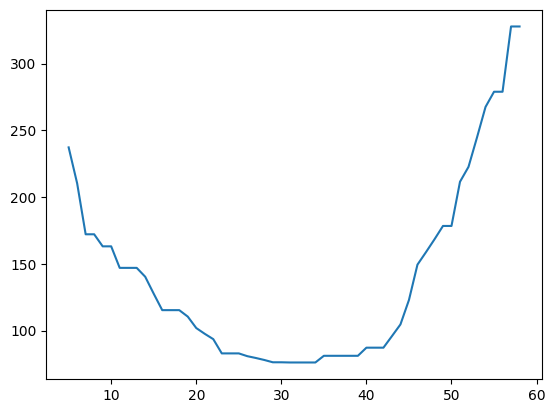

In [27]:
# Find the core region and the area of the image to be scanned

x = []
y = []

for i in range(5, int(tfp.stats.percentile(Vals, 90)), 1):
    x.append(i)

    y.append(GetVariance(Vals, i))

plt.plot(x, y)

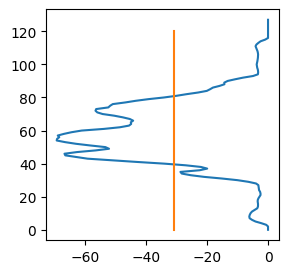

In [28]:
core_threshold = x[y.index(min(y))]

plt.figure(figsize=(3,3))
base = plt.gca().transData
rot = transforms.Affine2D().rotate_deg(90)

plt.plot(Vals, transform = rot + base)

plt.plot([-core_threshold, -core_threshold], [-0, 120])

In [29]:
above_threshold_mask = tf.math.greater(Vals, core_threshold)
locs = tf.where(above_threshold_mask)
core_region_base = int(locs[-1])
core_width = len(locs)

In [30]:
low_limit = int(core_region_base - 0.25 * core_width)
upper_limit = int(core_region_base + 0.25 * core_width)

In [31]:
for i in range(low_limit, upper_limit):
    print(i)

69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89


In [32]:
base = []

for column in range(len(image)):
    line = 0
    found = False # To reset
    index = 0
    val_max = 0 # To reset

    for i in range(low_limit, upper_limit):
        # print(image[column][i])
        if image[column][i] != 0 and found == False:
            line += 1
            found = True
            if image[column][i] > val_max:
                index = i
                val_max = image[column][i]

        elif image[column][i] != 0 and found == True:
            if image[column][i] > val_max:
                index = i
                val_max = image[column][i]        

        elif image[column][i] == 0 and found == True:   
            found = False
            val_max = 0

    if image[column][upper_limit] == 0: # This prevents lines which extend below from being counted
        base.append(index)
    else:
        base.append(0)

print(base)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 76, 71, 73, 73, 73, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 85, 85, 85, 85, 85, 0, 0, 0, 0, 69, 69, 69, 69, 70, 70, 71, 71, 72, 73, 73, 73, 73, 73, 73, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 70, 71, 71, 71, 71, 71, 71, 71, 71, 71, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 69, 69, 70, 70, 73, 74, 74, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 70, 69, 69, 73, 73, 70, 70, 73, 73, 73, 69, 69, 69, 69, 69, 69, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 69, 69, 69, 73, 74, 75, 76, 76, 76, 76, 76, 78, 0, 0, 0, 0, 0, 69, 69, 69, 70, 70, 73, 75, 75, 76, 78, 79, 79, 79, 79, 78, 78, 78, 78, 77, 77, 76, 76, 76, 76, 75, 75, 75, 75, 73, 73, 73, 73, 73, 74, 74, 74, 73, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 69, 69, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [33]:
line = 0
found = False # To reset
index = 0
val_max = 0
val_max_list = []
val_max_indices = []

for i in range(len(base)):
    print(found)
    if base[i] != 0 and found == False:
        line += 1
        found = True
        if base[i] > val_max:
            index = i
            val_max = base[i]

    elif base[i] != 0 and found == True:
        if base[i] > val_max:
            index = i
            val_max = base[i]        

    elif base[i] == 0 and found == True:   
        found = False
        val_max_list.append(val_max)
        val_max_indices.append(index)
        val_max = 0

print(val_max_indices)
print(val_max_list)

val_max_indices = tf.reshape(tf.constant(val_max_indices), [len(val_max_indices),1])
val_max_list =  tf.reshape(tf.constant(val_max_list), [len(val_max_list),1])

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
True
True
True
True
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
True
True
True
True
False
False
False
False
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
True
True
True
True
True
True
True
True
True
False
False
False
False
False
False
False
False
False
False
False
False
True
True
True
True
True
True
True
False
False
False
False
False
False
False
False
Fals

In [34]:
line = LinearRegression().fit(val_max_indices, val_max_list)

In [35]:
rotate = - math.atan(line.coef_[0][0]) * 180 / math.pi
image = RotateImage(image, rotate)

In [36]:
rotate

-0.29147659638846185

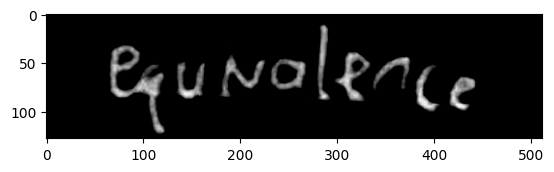

In [37]:
DisplayWord(image)

Slant removal

In [38]:
def shear_image(image, angle):
    """
    Shear a TensorFlow image by a given angle.

    Parameters:
    - image: TensorFlow tensor, input image (batched or not)
    - angle: float, shear angle in radians

    Returns:
    - sheared_image: TensorFlow tensor, sheared image
    """
    # Get image shape
    image_shape = tf.shape(image)

    # Create shear matrix
    shear_matrix = tf.raw_ops.AffineWarpImage(
        images=tf.expand_dims(image, axis=0),  # Batch dimension
        transforms=tf.convert_to_tensor([[[np.cos(angle), -np.sin(angle), 0.0],
                                          [np.sin(angle), np.cos(angle), 0.0]]],
                                        dtype=tf.float32),
        output_shape=image_shape
    )

    # Extract the sheared image from the batch
    sheared_image = shear_matrix[0]

    return sheared_image

In [39]:
# Shear investigation function

def ShearTest(image, InitAngle, reps):
    # When reps = 1, the function takes around 1.5 s to run

    scores = []

    image = tf.reshape(image, [image_width, image_height])
    image = tf.reshape(image, [1, image_width, image_height])

    shear = tf.keras.preprocessing.image.apply_affine_transform(image, theta = InitAngle, shear = -InitAngle)

    Hist = HorizontallHistorgram(shear)

    Score = tf.math.reduce_sum(tf.math.square(Hist))

    scores.append(Score)

    for i in range(reps):
        shear = tf.keras.preprocessing.image.apply_affine_transform(shear, theta = InitAngle, shear = -InitAngle)

        # DisplayWord(shear)
        
        Hist = HorizontallHistorgram(shear)

        # plt.plot(Hist)
        # plt.show()

        Score = tf.math.reduce_sum(tf.math.square(Hist))

        scores.append(Score)
    
    scores = tf.stack(scores)
    return scores


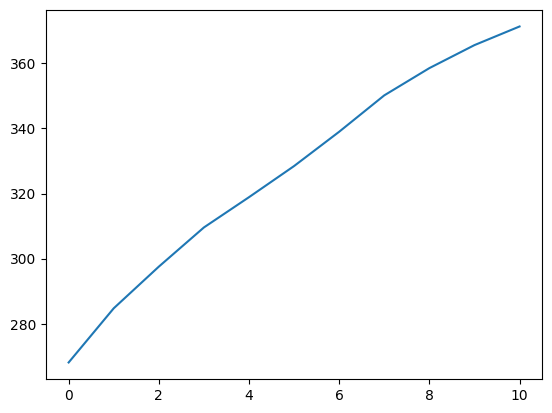

In [40]:
scores = ShearTest(image, -0.5, 10)

plt.plot(scores)
plt.show()

In [41]:
# Shear investigation function

def ShearTest2(image, angle, reps):
    # When reps = 1, the function takes around 1.5 s to run

    scores = []

    image = tf.reshape(image, [image_width, image_height])
    image = tf.reshape(image, [1, image_width, image_height])

    for rep in range(reps):

        InitAngle = rep * angle

        print(InitAngle)

        shear = tf.keras.preprocessing.image.apply_affine_transform(image, theta = InitAngle, shear = -InitAngle)

        # DisplayWord(shear)
        
        Hist = HorizontallHistorgram(shear)

        # plt.plot(Hist)
        # plt.show()

        Score = tf.math.reduce_sum(tf.math.square(Hist))

        scores.append(Score)
    
    scores = tf.stack(scores)
    return scores


In [42]:
def GetShearAngle(image):
    rep = 20
    max_angle = 10

    angle = max_angle / rep

    positive = ShearTest2(image, angle, rep)
    negative = ShearTest2(image, - angle, rep)

    score = tf.concat([negative, positive], 0)

    sorted_indices = tf.argsort(score)
    index_min = sorted_indices[2].numpy()

    shear_angle = ( index_min - rep ) * angle

    print(f"Shear angle : {shear_angle}")

    return shear_angle

0.0


0.5
1.0
1.5
2.0
2.5
3.0
3.5
4.0
4.5
5.0
5.5
6.0
6.5
7.0
7.5
8.0
8.5
9.0
9.5
-0.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
-4.5
-5.0
-5.5
-6.0
-6.5
-7.0
-7.5
-8.0
-8.5
-9.0
-9.5
Shear angle : 1.5


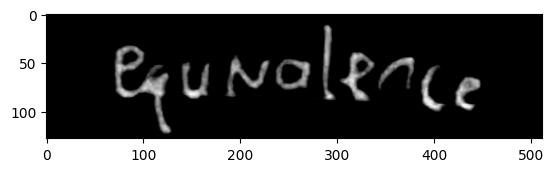

In [43]:
ShearAngle = GetShearAngle(image)

image = tf.reshape(image, [image_width, image_height])
image = tf.reshape(image, [1, image_width, image_height])

shear = tf.keras.preprocessing.image.apply_affine_transform(image, theta = ShearAngle, shear = - ShearAngle)

DisplayWord(shear)

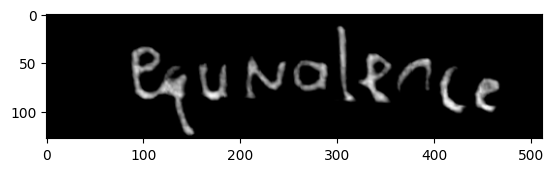

In [44]:
ShearAngle =  7

image = tf.reshape(image, [image_width, image_height])
image = tf.reshape(image, [1, image_width, image_height])

shear = tf.keras.preprocessing.image.apply_affine_transform(image, theta = ShearAngle, shear = - ShearAngle)

DisplayWord(shear)

In [45]:
image = shear

Make the characters 1 pixel wide

In [46]:
image = tf.reshape(image, [image_width, image_height])

skeleton = thin(image, max_num_iter=10)

# or skeletonize(image)

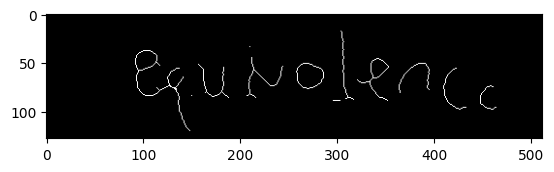

In [47]:
DisplayWord(skeleton)

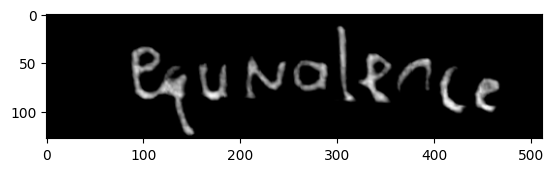

In [48]:
DisplayWord(image)

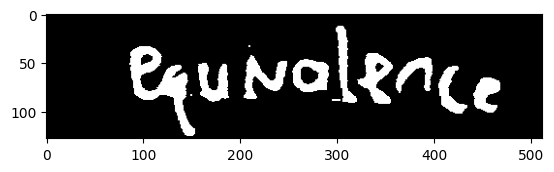

In [49]:
def convert_non_zero_to_one(tensor):
    # Create a boolean mask for non-zero values
    non_zero_mask = tf.math.not_equal(tensor, 0)
    
    # Convert non-zero values to 1 using the boolean mask
    result_tensor = tf.where(non_zero_mask, 1, tensor)
    
    return result_tensor

DisplayWord(convert_non_zero_to_one(image))

In [50]:
def SoftenImage(word, CleaningIndex):
    # CleaningIndex is a value from 0 to 10. Higher the value, the more of the high stress areas will be highlighted.


    word = tf.constant(np.where(word < CleaningIndex / 10, 0, word))

    return tf.constant(word)

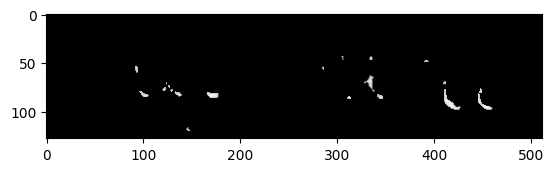

In [51]:
DisplayWord(SoftenImage(image, 7))

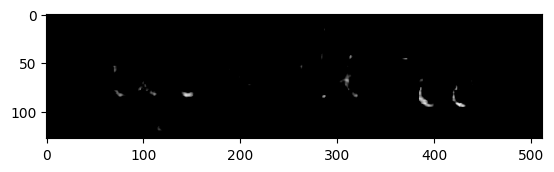

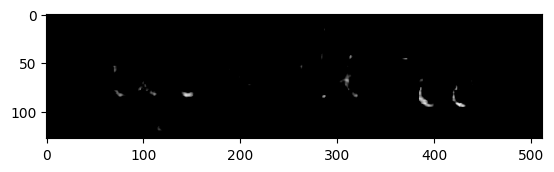

In [52]:
DisplayWord(BgChangeOptimised(word, 11))

# Charcter segmentation

In [53]:
# All this is for the purpose of visualising the points at which the breaks needed to be drawn

def DrawVertical(x_position, image):

    height, width = image.shape
    mask = tf.zeros_like(image)
    mask = tf.concat([image[:x_position, :], tf.ones([1, width]), image[x_position+1:, :]], axis=0)  # White vertical line

    return mask

def DrawBoundaries(positions, image):
    LinedImg = DrawVertical(positions[0], image)

    for i in range(1, len(positions)):
        LinedImg = DrawVertical(positions[i], LinedImg)

    DisplayWord(LinedImg)

    return LinedImg


In [54]:
TempImg = tf.math.square(image)

sums = tf.reduce_sum(TempImg, axis=1)
positions = tf.range(0, image_width, dtype=tf.float32)

NewSegment = tf.Variable(256)

In [55]:

def LossFnSegments(segments):

    # segments = [NewSegment, image_width]

    # The following determines the loss for a given array segments

    segments.sort()

    VarTotal = 0

    prev = 0

    Averages = []

    for i in range(len(segments)):

        Avg = tf.math.reduce_sum(tf.math.multiply(sums[prev:segments[i]], positions[prev:segments[i]])) / tf.math.reduce_sum(sums[prev:segments[i]])

        VarTotal += tf.math.sqrt(tf.math.reduce_sum(tf.math.multiply(tf.math.square(positions[prev:segments[i]] - Avg), sums[prev:segments[i]])) / tf.math.reduce_sum(sums[prev:segments[i]]))

        Averages.append(Avg)

        prev = segments[i]

    loss = VarTotal - tf.math.reduce_variance(tf.stack(Averages)) / 100

    if math.isnan(loss.numpy()):
        return 0

    return loss.numpy()

This approach finds additional lines in a greedy fashion over the entire image.

[511]


-13.382492
[188, 511]
-90.5282
[188, 468, 511]
-140.80722


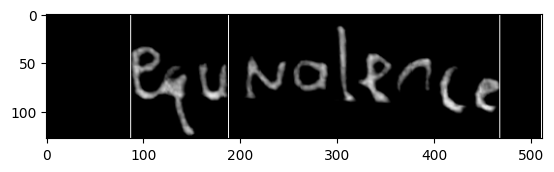

<tf.Tensor: shape=(512, 128), dtype=float32, numpy=
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 1., 1., ..., 1., 1., 1.]], dtype=float32)>

In [56]:
segments = [image_width - 1]

for i in range(3):
    
    losses = []

    segmentsNew = segments

    print(segments)

    for i in range(len(sums)):
        segmentsNew = segmentsNew + [i]
        losses.append(LossFnSegments(segmentsNew))
        segmentsNew = segments

    # plt.plot(losses)
    # plt.show()

    print(min(losses))

    segments.append(losses.index(min(losses)))
    segments.sort()

DrawBoundaries(segments, image)

This method finds the local minima of the loss function all across the image rather than just the global minima

The local minima are found in two ways: one using the derivative and the other comparing surrounding values

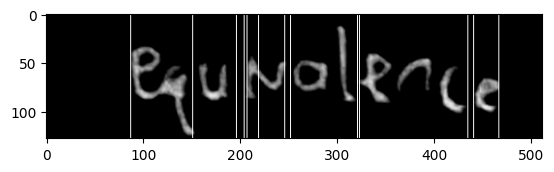

<tf.Tensor: shape=(512, 128), dtype=float32, numpy=
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)>

In [57]:
def find_local_minima(data):
    """
    Find the local minima in a list of data.

    Parameters:
        data (list): A list representing the graph data.

    Returns:
        list: A list containing the indices of the local minima.
    """
    local_minima = []

    # Check each element in the list except the first and last
    for i in range(1, len(data) - 1):
        if data[i] < data[i - 1] and data[i] < data[i + 1]:
            local_minima.append(i)

    return local_minima

zeros = find_local_minima(losses)

DrawBoundaries(zeros, image)

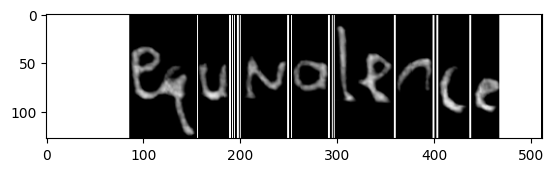

In [58]:
dx = 1
dy = np.diff(losses) / dx

# plt.plot(dy)
# plt.show()

zeros = []

for i in range(len(dy)):
    if dy[i] == 0:
        # print(i)
        zeros.append(i)

# print(zeros[5])
LinedImg = DrawVertical(zeros[0], image)
# DisplayWord(LinedImg)

for i in range(1, len(zeros)):
    LinedImg = DrawVertical(zeros[i], LinedImg)

DisplayWord(LinedImg)

Here we use a decision tree approach

In [61]:
def LossFnTree(begin, end, split):

    local_segments = [split, end]

    VarTotal = 0

    prev = begin

    Averages = []

    for i in range(len(local_segments)):

        Avg = tf.math.reduce_sum(tf.math.multiply(sums[prev:local_segments[i]], positions[prev:local_segments[i]])) / tf.math.reduce_sum(sums[prev:local_segments[i]])

        VarTotal += tf.math.sqrt(tf.math.reduce_sum(tf.math.multiply(tf.math.square(positions[prev:local_segments[i]] - Avg), sums[prev:local_segments[i]])) / tf.math.reduce_sum(sums[prev:local_segments[i]]))

        Averages.append(Avg)

        prev = local_segments[i]

    if math.isnan(VarTotal.numpy()):
        loss0 = 0
    else:
        loss0 = VarTotal.numpy()

    if math.isnan(tf.math.reduce_variance(tf.stack(Averages)).numpy()):
        loss1 = 0
    else:
        loss1 = tf.math.reduce_variance(tf.stack(Averages)).numpy()

    if math.isnan(abs((end - split) - (split - begin))):
        loss2 = 0
    else:
        loss2 = abs((end - split) - (split - begin))

    return [loss0, loss1, loss2]

In [62]:
def Normalise(l, m): # Get the value to between 1 and m
    factor = max(l) / m

    try:
        return [ e/factor for e in l]
    except ZeroDivisionError:
        return l

In [100]:
def TreeSegmentation(segments, threshold):    
    differences = [segments[i + 1] - segments[i] for i in range(len(segments) - 1)]

    while True:

        if sum([True if j < threshold else False for j in differences]) == 1:
            index = -2
        elif sum([True if j < threshold else False for j in differences]) == 0:
            index = 0
        else:
            break

        begin = segments[index]
        end = segments[index + 1]

        losses = []

        for split in range(begin, end):
            losses.append(LossFnTree(begin, end, split))

        loss0 = [i[0] for i in losses]
        loss1 = [i[1] for i in losses]
        loss2 = [i[2] for i in losses]

        loss0 = Normalise(loss0, 10)
        loss1 = Normalise(loss1, 15)
        loss2 = Normalise(loss2, 5)

        losses = [ loss0[i] - loss1[i] + loss2[i] for i in range(len(losses))]

        # plt.plot(losses)
        # plt.show()

        segments.append(losses.index(min(losses)) + begin)

        segments.sort()

        print(segments)

        differences = [segments[i + 1] - segments[i] for i in range(len(segments) - 1)]

    DrawBoundaries(segments, image)

    return segments, differences

[86, 272, 469]
[86, 186, 272, 469]
[86, 151, 186, 272, 469]
[86, 118, 151, 186, 272, 469]
[86, 117, 118, 151, 186, 272, 469]
[86, 117, 118, 151, 186, 272, 371, 469]
[86, 117, 118, 151, 186, 272, 371, 429, 469]
[86, 117, 118, 151, 186, 272, 371, 429, 442, 469]
[86, 117, 118, 151, 186, 272, 371, 429, 442, 468, 469]


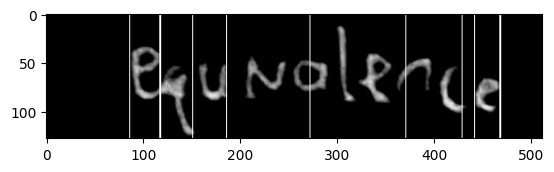

In [101]:
segments, differences = TreeSegmentation([tf.argmax(tf.cast(tf.not_equal(sums, 0), tf.int32), output_type=tf.int32).numpy(), image_width - tf.argmax(tf.cast(tf.not_equal(tf.reverse(sums, axis=[0]), 0), tf.int32), output_type=tf.int32).numpy()], threshold = int(image_width / 50))

[118, 119, 151]
[118, 119, 120, 151]


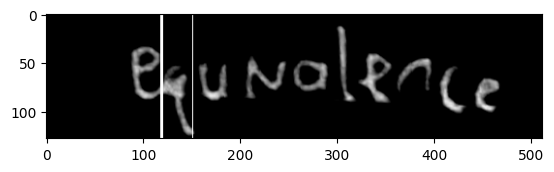

[151, 157, 186]


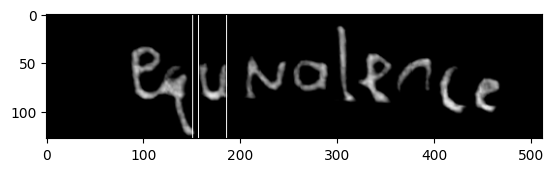

[186, 205, 272]
[186, 205, 247, 272]


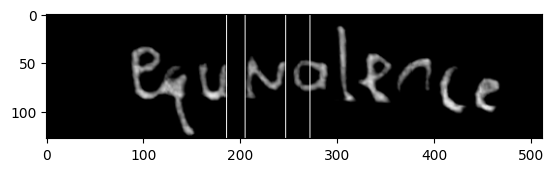

[272, 321, 371]
[272, 296, 321, 371]


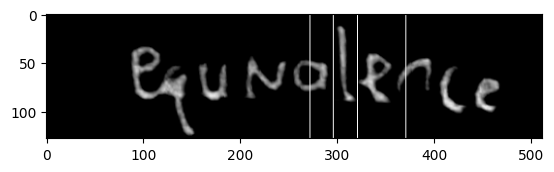

[371, 400, 429]


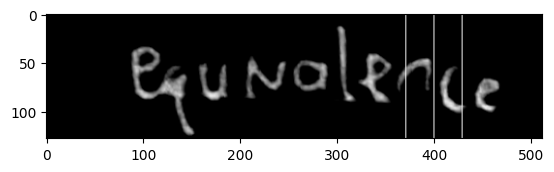

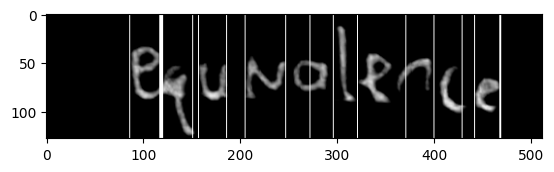

<tf.Tensor: shape=(512, 128), dtype=float32, numpy=
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)>

In [102]:
avg_diff = sum(differences) / ( len(differences) + 2 )

new_segments = []

for i in range(len(differences)):
    if differences[i] > avg_diff:
        n, d = TreeSegmentation([segments[i], segments[i + 1]], threshold = avg_diff)
        new_segments += n

DrawBoundaries(list(set(new_segments + segments)), image)